In [2]:
pip install -U langgraph langchain langchain-core wikipedia-api pydantic ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install -U langchain-groq

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install wikipedia-api

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv(override=True)  
assert os.getenv("GROQ_API_KEY"), "API_KEY not found."

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.1
)


In [6]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain.chat_models import init_chat_model
from langgraph.graph import MessagesState
import operator
from typing import Annotated

from langgraph.graph import add_messages
from langchain_core.messages import SystemMessage

In [7]:
class ResearcherState(TypedDict):
    task: str
    research: str
    messages: Annotated[list, add_messages]
    trace: Annotated[list, operator.add]
    

    

In [8]:
#Resarcher Graph

from langgraph.prebuilt import ToolNode
import wikipediaapi
from langchain_core.tools import tool

wiki_wiki = wikipediaapi.Wikipedia(
    user_agent="LangGraphAssignment/1.0 (student@example.com)",
    language="en"
)


@tool


def wikipedia_search(query: str):
    
    """Search Wikipedia and return raw page content for the given topic."""
    
    results = wiki_wiki.search(query, limit=3)
    research = []
    
    for title, page in results.pages.items():
        research.append(f"# {title}\n{page.text[:3000]}")

    return "\n\n".join(research)


tools = [wikipedia_search]
llm_with_tools = llm.bind_tools(tools)


from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

def Researcher(state):
    messages = state["messages"]

    if not messages:
        messages = [HumanMessage(content=state["task"])]

    response = llm_with_tools.invoke([
        SystemMessage(content="""
        You are a researcher.
        Research the given task using Wikipedia.
        Collect raw information only.
        Do not summarize or format the research.
        """),
        *messages
    ])

    research = "\n\n".join(
        msg.content for msg in messages
        if isinstance(msg, ToolMessage) # pyright: ignore[reportArgumentType]
    ) # type: ignore

    return {
        "research": research,
        "messages": [response],
        "trace": ["researcher"]
    }

def route(state: ResearcherState):
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return END    
    
builder=StateGraph(ResearcherState)
builder.add_node("researcher", Researcher)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "researcher")
builder.add_conditional_edges(
    "researcher",
    route,
    {
        "tools": "tools",
        END: END
    }
)

builder.add_edge("tools", "researcher")





In [9]:
#Test researcher graph
researcher_graph = builder.compile()

result = researcher_graph.invoke({
    "task": "Research artificial intelligence and its applications and provide raw information from Wikipedia. also provide the references of the information you have provided.and check if the info are correct or not and if they are correct then provide the references of the information you have provided.",
    "research": "",
    "messages": [],
    "trace": []
})

print("RESEARCH:")
print(result["research"])

print("\nTRACE:")
print(result["trace"])

RESEARCH:
# Artificial intelligence
Artificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is also a field of research spanning computer science, engineering, and mathematics that develops and studies methods and software enabling machines to perceive their environment and use learning and intelligence to take actions that maximise their chances of achieving defined goals.
Prominent applications of AI include advanced web search engines, chatbots, virtual assistants, autonomous vehicles, play and analysis in strategy games (e.g., chess and Go), and content generation (e.g., text, images, audio, and videos).
The traditional goals of AI research include learning, reasoning, knowledge representation, planning, natural language processing, and perception, as well as support for robotics. To reach these goals, AI researchers use te

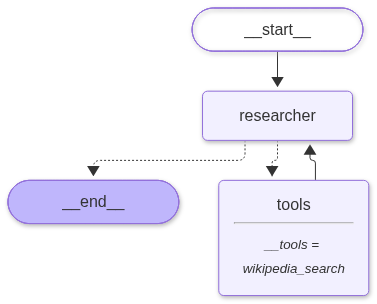

In [10]:
from IPython.display import Image, display

display(
    Image(
        researcher_graph.get_graph().draw_mermaid_png()
    )
)

In [11]:
class WriterState(TypedDict):
    task: str
    research: str
    feedback: str
    draft: str
    attempts: int
    messages: Annotated[list, add_messages]
    trace: Annotated[list, operator.add]

In [12]:
#writer graph

def writer(state):

    prompt = f"""
    You are a professional writer. 

    Task:
    {state["task"]}

    Research material:
    {state["research"]}

    Reviewer feedback:
    {state["feedback"]}

    Write the requested content using the research if available.
    If feedback is provided, revise the previous draft accordingly.
    """

    response = llm.invoke(prompt)

    return {
        "draft": response.content,
        "attempts": state["attempts"] + 1,
        "messages": [response],
        "trace": ["writer"]
    }
    
builder = StateGraph(WriterState)

builder.add_node("writer", writer)

builder.add_edge(START, "writer")
builder.add_edge("writer", END)

writergraph = builder.compile()

result = writergraph.invoke({
    
    "task": "Write a 3-sentence pitch for a plant-watering mobile app. The app should help users track their plants' watering schedules and provide reminders. Use the research provided to support your pitch.",
    "research": "",
    "feedback": "",
    "draft": "",
    "attempts": 0,
    "messages": [],
    "trace": []
})

print(result)

{'task': "Write a 3-sentence pitch for a plant-watering mobile app. The app should help users track their plants' watering schedules and provide reminders. Use the research provided to support your pitch.", 'research': '', 'feedback': '', 'draft': 'Meet your green thumb’s new sidekick: a sleek mobile app that automatically logs each plant’s watering needs, syncs with your calendar, and learns optimal intervals based on species and climate. Real‑time reminders pop up just before a plant gets thirsty, while a visual dashboard shows every pot’s health at a glance. With smart analytics and customizable alerts, you’ll never over‑ or under‑water again—keeping your indoor jungle thriving with minimal effort.', 'attempts': 1, 'messages': [AIMessage(content='Meet your green thumb’s new sidekick: a sleek mobile app that automatically logs each plant’s watering needs, syncs with your calendar, and learns optimal intervals based on species and climate. Real‑time reminders pop up just before a plan

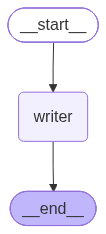

In [13]:
from IPython.display import Image, display

display(
    Image(writergraph.get_graph().draw_mermaid_png())
)

In [14]:
from pydantic import BaseModel, Field
from langchain_core.messages import AIMessage

class ReviewerState(TypedDict):
    task: str
    draft: str
    feedback: str
    approved: bool
    messages: Annotated[list, add_messages]
    trace: Annotated[list, operator.add]

In [15]:
#reviewer graph


class Reviewr(BaseModel):
    feedback: str = Field(
        description="Specific, actionable feedback on the draft."
    )
    approved: bool = Field(
        description="True if the draft is good enough to publish."
    )
    
    
reviewer_llm = llm.with_structured_output(Reviewr)    

def Reviewer(state: ReviewerState):

    prompt = f"""
    You are a professional reviewer.

    Original task:
    {state["task"]}

    Draft:
    {state["draft"]}

    Evaluate whether the draft satisfies the original task.

    If it needs improvement:
    - Set approved to False.
    - Give specific, actionable feedback.

    If it meets the requirements:
    - Set approved to True.
    - Explain briefly why it is acceptable.
    """

    review = reviewer_llm.invoke(prompt)

    return {
        "feedback": review.feedback,
        "approved": review.approved,
        "messages": [AIMessage(content=review.feedback)],
        "trace": ["reviewer"]
    }
    
builder = StateGraph(ReviewerState)

builder.add_node("reviewer", Reviewer)

builder.add_edge(START, "reviewer")
builder.add_edge("reviewer", END)

reviewer_app = builder.compile()    

result = reviewer_app.invoke({
    "task": "Write a short, engaging description for a new coffee brand that emphasizes its energizing qualities. in raw information format.",
    "draft": "Coffee that wakes you up and keeps you going.",
    "feedback": "",
    "approved": False,
    "messages": [],
    "trace": []
})

print(result)

{'task': 'Write a short, engaging description for a new coffee brand that emphasizes its energizing qualities. in raw information format.', 'draft': 'Coffee that wakes you up and keeps you going.', 'feedback': 'The draft is very brief and mentions the energizing effect, but it lacks the engaging, vivid language expected for a brand description. Consider adding sensory details (e.g., aroma, flavor), a hint of the brand\'s personality, and a more dynamic verb phrase to make it compelling. For example: "Bold, aromatic coffee that jolts you awake and fuels your day with unstoppable energy." This keeps it short, raw, and emphasizes the energizing qualities more effectively.', 'approved': False, 'messages': [AIMessage(content='The draft is very brief and mentions the energizing effect, but it lacks the engaging, vivid language expected for a brand description. Consider adding sensory details (e.g., aroma, flavor), a hint of the brand\'s personality, and a more dynamic verb phrase to make it 

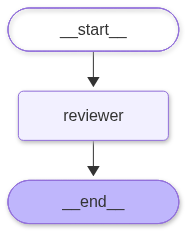

In [16]:
from IPython.display import Image, display

display(
    Image(reviewer_app.get_graph().draw_mermaid_png())
)

In [17]:
class OrchestratorState(TypedDict):
    task: str
    research: str
    draft: str
    feedback: str
    approved: bool
    attempts: int
    trace: Annotated[list, operator.add]

In [18]:
def run_researcher(state: OrchestratorState):

    result = researcher_graph.invoke({
        "task": state["task"],
        "research": "",
        "messages": [],
        "trace": []
    })

    return {
        "research": result["research"],
        "trace": result["trace"]
    }
def route_after_review(state: OrchestratorState):

    max_attempts = 3

    if state["approved"]:
        return END

    if state["attempts"] >= max_attempts:
        return END

    return "writer" 
def run_writer(state: OrchestratorState):

    result = writergraph.invoke({
        "task": state["task"],
        "research": state["research"],
        "feedback": state["feedback"],
        "draft": state["draft"],
        "attempts": state["attempts"],
        "messages": [],
        "trace": []
    })

    return {
        "draft": result["draft"],
        "attempts": result["attempts"],
        "trace": result["trace"]
    }
def run_reviewer(state: OrchestratorState):

    result = reviewer_app.invoke({
        "task": state["task"],
        "draft": state["draft"],
        "feedback": "",
        "approved": False,
        "messages": [],
        "trace": []
    })

    return {
        "feedback": result["feedback"],
        "approved": result["approved"],
        "trace": result["trace"]
    }    
builder = StateGraph(OrchestratorState)

builder.add_node("researcher", run_researcher)
builder.add_node("writer", run_writer)
builder.add_node("reviewer", run_reviewer)

builder.add_edge(START, "researcher")
builder.add_edge("researcher", "writer")
builder.add_edge("writer", "reviewer")

builder.add_conditional_edges(
    "reviewer",
    route_after_review,
    {
        "writer": "writer",
        END: END
    }
)

multi_agent_app = builder.compile()   

In [19]:
result = multi_agent_app.invoke({
    "task": "Write a short description for a new ice cream flavor.",
    "research": "",
    "draft": "",
    "feedback": "",
    "approved": False,
    "attempts": 0,
    "trace": []
})

print("Final Draft:", result["draft"])
print("Approved:", result["approved"])
print("Attempts:", result["attempts"])
print("Trace:", result["trace"])

Final Draft: Midwest Sunrise blends smooth vanilla ice cream with a ribbon of tangy blueberry‑Blue Moon and a burst of sweet strawberry, creating a bright red‑blue‑yellow swirl. Inspired by the legendary Midwest Superman ice cream, it captures the hero’s colors in a fresh, fruit‑forward twist.
Approved: True
Attempts: 2
Trace: ['researcher', 'researcher', 'researcher', 'researcher', 'writer', 'reviewer', 'writer', 'reviewer']


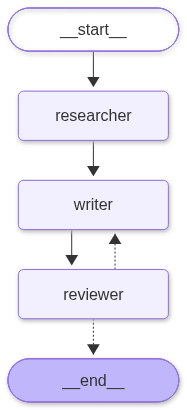

In [20]:
display(Image(multi_agent_app.get_graph().draw_mermaid_png()))